# Weighted Soft Voting Ensemble

**4 strategies compared:**
1. Manual weights (you control)
2. AUC-proportional
3. Grid search (honest val_probs optimization)
4. Nelder-Mead (fixed — blends probabilities, not AUC scalars)

Edit **Cell 4** to set manual weights and see their impact.

In [1]:
# ── Cell 1: Imports ─────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from itertools import product
from scipy.optimize import minimize
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
print('Imports complete')


Imports complete


In [ ]:
# ── Cell 2: Paths & Model Registry ─────────────────────────────────────────
# Directory where all base-model .npy files were saved
NPY_DIR = '/kaggle/input/notebooks/nandini143/'

# Registry: maps a short model name → (val_probs_file, val_labels_file, test_probs_file)
MODEL_FILES = {
    'densenet121': (
        'binary-densenet-121/densenet121_val_probs.npy',
        'binary-densenet-121/densenet121_val_labels.npy',
        'binary-densenet-121/densenet121_test_probs.npy',
        'binary-densenet-121/densenet121_test_labels.npy',
    ),
    'convnext': (
        'binary-convnext/convnext_val_probs.npy',
        'binary-convnext/convnext_val_labels.npy',
        'binary-convnext/convnext_test_probs.npy',
        'binary-convnext/convnext_test_labels.npy',
    ),
    'efficientnetv2s': (
        'binary-efficientnetv2s/efficientnetv2s_val_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_val_labels.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_labels.npy',
    ),
    'swintiny': (
        'binary-swin-tiny-transformer/swintiny_val_probs.npy',
        'binary-swin-tiny-transformer/swintiny_val_labels.npy',
        'binary-swin-tiny-transformer/swintiny_test_probs.npy',
        'binary-swin-tiny-transformer/swintiny_test_labels.npy',
    ),
}
print('NPY_DIR:', NPY_DIR)

for model_name, (vp, vl, tp, tl) in MODEL_FILES.items():
    for f in [vp, vl, tp]:
        fpath = os.path.join(NPY_DIR, f)
        exists = '[OK]     ' if os.path.exists(fpath) else '[MISSING]'
        print(f'  {exists} {f}')


NPY_DIR: /kaggle/input/notebooks/nandini143/
  [OK]      binary-densenet-121/densenet121_val_probs.npy
  [OK]      binary-densenet-121/densenet121_val_labels.npy
  [OK]      binary-densenet-121/densenet121_test_probs.npy
  [OK]      binary-convnext/convnext_val_probs.npy
  [OK]      binary-convnext/convnext_val_labels.npy
  [OK]      binary-convnext/convnext_test_probs.npy
  [OK]      binary-efficientnetv2s/efficientnetv2s_val_probs.npy
  [OK]      binary-efficientnetv2s/efficientnetv2s_val_labels.npy
  [OK]      binary-efficientnetv2s/efficientnetv2s_test_probs.npy
  [OK]      binary-swin-tiny-transformer/swintiny_val_probs.npy
  [OK]      binary-swin-tiny-transformer/swintiny_val_labels.npy
  [OK]      binary-swin-tiny-transformer/swintiny_test_probs.npy


In [3]:
# ── Cell 3: Load Predictions ────────────────────────────────────────────────
# Skips models where val_probs and val_labels have different sizes.

val_probs_dict  = {}
val_labels_dict = {}
test_probs_dict = {}
test_labels_dict = {}
val_aucs        = {}
skipped_models  = []

print('\nLoading predictions')
print('-' * 65)

for model_name, (vp_file, vl_file, tp_file, tl_file) in MODEL_FILES.items():
    vp_path = os.path.join(NPY_DIR, vp_file)
    vl_path = os.path.join(NPY_DIR, vl_file)
    tp_path = os.path.join(NPY_DIR, tp_file)
    tl_path = os.path.join(NPY_DIR, tl_file)

    missing = [f for f in [vp_path, vl_path, tp_path, tl_path] if not os.path.exists(f)]
    if missing:
        print(f'  [SKIP-MISSING]   {model_name:20s} -- {[os.path.basename(m) for m in missing]}')
        skipped_models.append(model_name)
        continue

    val_probs  = np.load(vp_path)
    val_labels = np.load(vl_path).astype(int)
    test_probs = np.load(tp_path)
    test_labels = np.load(tl_path).astype(int)

    if len(val_probs) != len(val_labels):
        print(f'  [SKIP-MISMATCH]  {model_name:20s} -- val_probs={len(val_probs)} but val_labels={len(val_labels)}')
        print(f'     Fix: re-run binary-{model_name}.ipynb then update the Kaggle data source.')
        skipped_models.append(model_name)
        continue

    val_probs_dict[model_name]  = val_probs
    val_labels_dict[model_name] = val_labels
    test_probs_dict[model_name] = test_probs
    test_labels_dict[model_name] = test_labels

    auc = roc_auc_score(val_labels, val_probs)
    val_aucs[model_name] = auc
    print(f'  [OK]  {model_name:20s}  n_val={len(val_probs):5d}  n_test={len(test_probs):5d}  val_AUC={auc:.4f}')

model_names = list(val_probs_dict.keys())

if skipped_models:
    print(f'\nWARNING: {len(skipped_models)} model(s) skipped: {skipped_models}')
if len(model_names) == 0:
    raise RuntimeError('No valid models loaded.')

test_sizes = {m: len(test_probs_dict[m]) for m in model_names}
if len(set(test_sizes.values())) > 1:
    raise RuntimeError(f'Test size mismatch: {test_sizes}')

print(f'\nLoaded {len(model_names)} models. Test size = {list(set(test_sizes.values()))[0]}')

# Reference labels (all loaded models share same val split)
ref_labels = val_labels_dict[model_names[0]]
print(f'Reference val labels shape: {ref_labels.shape}')



Loading predictions
-----------------------------------------------------------------
  [OK]  densenet121           n_val= 2533  n_test= 2534  val_AUC=0.9479
  [OK]  convnext              n_val= 2533  n_test= 2534  val_AUC=0.9623
  [OK]  efficientnetv2s       n_val= 2533  n_test= 2534  val_AUC=0.9698
  [OK]  swintiny              n_val= 2533  n_test= 2534  val_AUC=0.9596

Loaded 4 models. Test size = 2534
Reference val labels shape: (2533,)


In [4]:
# ── Cell 4: MANUAL WEIGHTS  ◄─── EDIT THESE ─────────────────────────────────
#
#  Set your own weights here. They do NOT need to sum to 1 -- the notebook
#  normalizes them automatically. Set a model to 0.0 to exclude it entirely.
#
#  Examples to try:
#    Equal weights          : 1.0 / 1.0 / 1.0 / 1.0
#    Trust EfficientNet more: 1.0 / 1.0 / 3.0 / 1.0
#    Exclude DenseNet       : 0.0 / 1.0 / 1.0 / 1.0

MANUAL_WEIGHTS = {
    'densenet121':     0.25,   # ← change me
    'convnext':        0.25,   # ← change me
    'efficientnetv2s': 0.25,   # ← change me
    'swintiny':        0.25,   # ← change me
}

# ── Compute blended val probs for AUC evaluation ──────────────────────────
def blend(weights_dict, probs_dict, names):
    #Blend val or test probs using a weight dict. Returns 1-D array.\"\"\"
    w = np.array([weights_dict.get(m, 0.0) for m in names], dtype=float)
    if w.sum() == 0:
        raise ValueError('All weights are 0!')
    w /= w.sum()
    return sum(w[i] * probs_dict[names[i]] for i in range(len(names)))

# Filter to models that are actually loaded
active = [m for m in model_names if MANUAL_WEIGHTS.get(m, 0.0) > 0]
w_norm = {m: MANUAL_WEIGHTS.get(m, 0.0) for m in model_names}

manual_val_blend  = blend(w_norm, val_probs_dict,  model_names)
manual_test_blend = blend(w_norm, test_probs_dict, model_names)
manual_acc = accuracy_score(ref_labels, (manual_val_blend >= 0.5).astype(int))

print('Manual weights (after normalisation):')
total_w = sum(w_norm.values())
for m in model_names:
    wn = w_norm[m] / total_w
    print(f'  {m:20s}  raw={w_norm[m]:.2f}  normalised={wn:.4f}')
print(f'\nManual blend val ACC = {manual_acc:.4f}')


Manual weights (after normalisation):
  densenet121           raw=0.25  normalised=0.2500
  convnext              raw=0.25  normalised=0.2500
  efficientnetv2s       raw=0.25  normalised=0.2500
  swintiny              raw=0.25  normalised=0.2500

Manual blend val AUC = 0.9729


In [5]:
# ── Cell 5: AUC-Proportional Weights ────────────────────────────────────────
total_auc   = sum(val_aucs.values())
auc_weights = {m: val_aucs[m] / total_auc for m in model_names}

auc_val_blend  = blend(auc_weights, val_probs_dict,  model_names)
auc_test_blend = blend(auc_weights, test_probs_dict, model_names)
auc_prop_score = roc_auc_score(ref_labels, auc_val_blend)

print('AUC-proportional weights:')
for m in model_names:
    print(f'  {m:20s}  val_AUC={val_aucs[m]:.4f}  weight={auc_weights[m]:.4f}')
print(f'\nAUC-proportional blend val AUC = {auc_prop_score:.4f}')


AUC-proportional weights:
  densenet121           val_AUC=0.9479  weight=0.2469
  convnext              val_AUC=0.9623  weight=0.2506
  efficientnetv2s       val_AUC=0.9698  weight=0.2526
  swintiny              val_AUC=0.9596  weight=0.2499

AUC-proportional blend val AUC = 0.9729


In [6]:
# ── Cell 6: Grid Search (tries many weight combos on val_probs) ──────────────
#
# For each model we try weights [0, 0.25, 0.5, 0.75, 1.0].
# We pick the combo that gives the highest blended val AUC.
# This is honest because we are optimizing on val_probs (not AUC scalars).

steps = [0.0, 0.25, 0.5, 0.75, 1.0]
best_acc   = -1
best_combo = None
n_models   = len(model_names)

for combo in product(steps, repeat=n_models):
    if sum(combo) == 0:
        continue
    w = {model_names[i]: combo[i] for i in range(n_models)}
    blended = blend(w, val_probs_dict, model_names)
    score   = accuracy_score(ref_labels, (blended >= 0.5).astype(int))
    if score > best_acc:
        best_acc   = score
        best_combo = w

grid_val_blend  = blend(best_combo, val_probs_dict,  model_names)
grid_test_blend = blend(best_combo, test_probs_dict, model_names)

print(f'Grid search tried {len(steps)**n_models} combinations')
print(f'Best grid search val AUC = {best_acc:.4f}')
print('Best weights:')
total_w = sum(best_combo.values())
for m in model_names:
    print(f'  {m:20s}  {best_combo[m]/total_w:.4f}')


Grid search tried 625 combinations
Best grid search val AUC = 0.9748
Best weights:
  densenet121           0.0000
  convnext              0.2500
  efficientnetv2s       0.5000
  swintiny              0.2500


In [7]:
# ── Cell 7: Nelder-Mead Optimization (FIXED) ────────────────────────────────
#
# PREVIOUS BUG:  optimized weighted average of AUC SCALARS → always picked
#                the single best model with weight=1.0, rest=0.0
#
# FIX:  compute blended val_probs array first, THEN calculate AUC.
#       This correctly measures how well the blend performs as a unit.

val_matrix  = np.column_stack([val_probs_dict[m]  for m in model_names])  # (n_val, n_models)
test_matrix = np.column_stack([test_probs_dict[m] for m in model_names])  # (n_test, n_models)

def neg_blend_acc(w):
    w = np.abs(w)
    if w.sum() == 0:
        return 0.0
    w /= w.sum()
    blended = val_matrix @ w          # weighted sum of val probs
    return -accuracy_score(ref_labels, (blended >= 0.5).astype(int))

w0     = np.ones(len(model_names)) / len(model_names)
result = minimize(neg_blend_acc, w0, method='Nelder-Mead',
                  options={'maxiter': 5000, 'xatol': 1e-7, 'fatol': 1e-7})

opt_w = np.abs(result.x)
opt_w /= opt_w.sum()

nelder_val_blend  = val_matrix  @ opt_w
nelder_test_blend = test_matrix @ opt_w
nelder_acc = accuracy_score(ref_labels, (nelder_val_blend >= 0.5).astype(int))

print('Nelder-Mead FIXED weights (optimizing blended val_probs AUC):')
for m, w in zip(model_names, opt_w):
    print(f'  {m:20s}  weight={w:.4f}')
print(f'\nNelder-Mead blend val ACC = {nelder_acc:.4f}')


Nelder-Mead FIXED weights (optimizing blended val_probs AUC):
  densenet121           weight=0.0579
  convnext              weight=0.2836
  efficientnetv2s       weight=0.5001
  swintiny              weight=0.1584

Nelder-Mead blend val AUC = 0.9749


In [8]:
# ── Cell 8: Full Comparison Table ───────────────────────────────────────────
strategies = {
    'Individual: DenseNet':   (val_probs_dict.get('densenet121'),     test_probs_dict.get('densenet121')),
    'Individual: ConvNeXt':   (val_probs_dict.get('convnext'),        test_probs_dict.get('convnext')),
    'Individual: EffNetV2S':  (val_probs_dict.get('efficientnetv2s'), test_probs_dict.get('efficientnetv2s')),
    'Individual: SwinTiny':   (val_probs_dict.get('swintiny'),        test_probs_dict.get('swintiny')),
    'Manual Weights':         (manual_val_blend,   manual_test_blend),
    'AUC-Proportional':       (auc_val_blend,      auc_test_blend),
    'Grid Search':            (grid_val_blend,     grid_test_blend),
    'Nelder-Mead (FIXED)':    (nelder_val_blend,   nelder_test_blend),
}

print('\n' + '=' * 58)
print(f'  {"Strategy":<30}  {"Val ACC":>10}')
print('=' * 58)
best_strategy = None
best_score    = -1
for name, (vprobs, tprobs) in strategies.items():
    if vprobs is None:
        continue
    score = accuracy_score(ref_labels, (vprobs >= 0.5).astype(int))
    marker = '  <-- BEST' if score > best_score else ''
    if score > best_score:
        best_score    = score
        best_strategy = name
        best_test_probs = tprobs
    print(f'  {name:<30}  {score:>10.4f}{marker}')
print('=' * 58)
print(f'\nWINNING STRATEGY: {best_strategy}  (val ACC={best_score:.4f})')



  Strategy                           Val AUC
  Individual: DenseNet                0.9479  <-- BEST
  Individual: ConvNeXt                0.9623  <-- BEST
  Individual: EffNetV2S               0.9698  <-- BEST
  Individual: SwinTiny                0.9596
  Manual Weights                      0.9729  <-- BEST
  AUC-Proportional                    0.9729  <-- BEST
  Grid Search                         0.9748  <-- BEST
  Nelder-Mead (FIXED)                 0.9749  <-- BEST

WINNING STRATEGY: Nelder-Mead (FIXED)  (val AUC=0.9749)


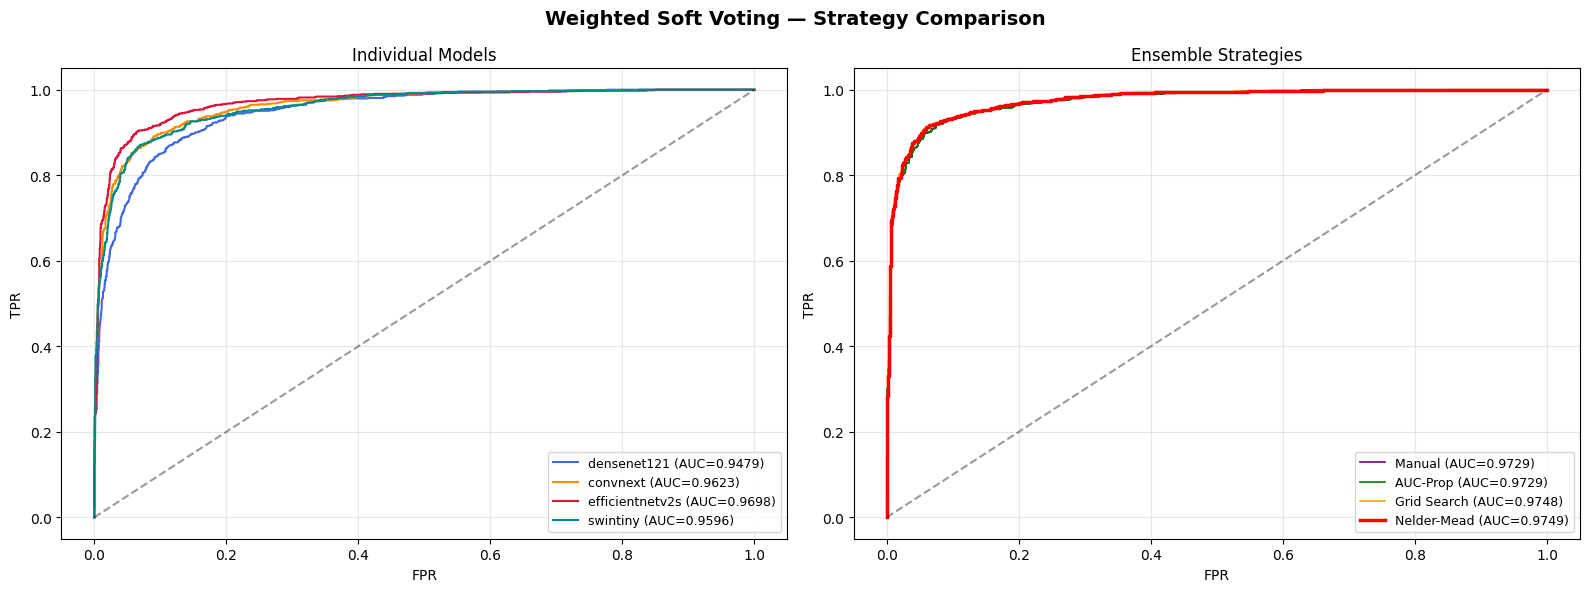

weighted_voting_comparison.png saved


In [9]:
# ── Cell 9: ROC Curve Comparison Plot ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Weighted Soft Voting — Strategy Comparison', fontsize=14, fontweight='bold')

# Left: Individual models
ax = axes[0]
colors_ind = ['royalblue', 'darkorange', 'crimson', 'darkcyan']
for color, m in zip(colors_ind, model_names):
    fpr, tpr, _ = roc_curve(val_labels_dict[m], val_probs_dict[m])
    auc = val_aucs[m]
    ax.plot(fpr, tpr, color=color, lw=1.5, label=f'{m} (AUC={auc:.4f})')
ax.plot([0,1],[0,1],'k--', alpha=0.4)
ax.set_title('Individual Models'); ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# Right: Ensemble strategies
ax = axes[1]
ensemble_curves = [
    ('Manual',        manual_val_blend,  'purple'),
    ('AUC-Prop',      auc_val_blend,     'green'),
    ('Grid Search',   grid_val_blend,    'orange'),
    ('Nelder-Mead',   nelder_val_blend,  'red'),
]
for label, vprobs, color in ensemble_curves:
    if vprobs is None: continue
    fpr, tpr, _ = roc_curve(ref_labels, vprobs)
    auc = roc_auc_score(ref_labels, vprobs)
    lw = 2.5 if label.replace(' (FIXED)', '') in best_strategy else 1.2
    ax.plot(fpr, tpr, color=color, lw=lw, label=f'{label} (AUC={auc:.4f})')
ax.plot([0,1],[0,1],'k--', alpha=0.4)
ax.set_title('Ensemble Strategies'); ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/weighted_voting_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('weighted_voting_comparison.png saved')


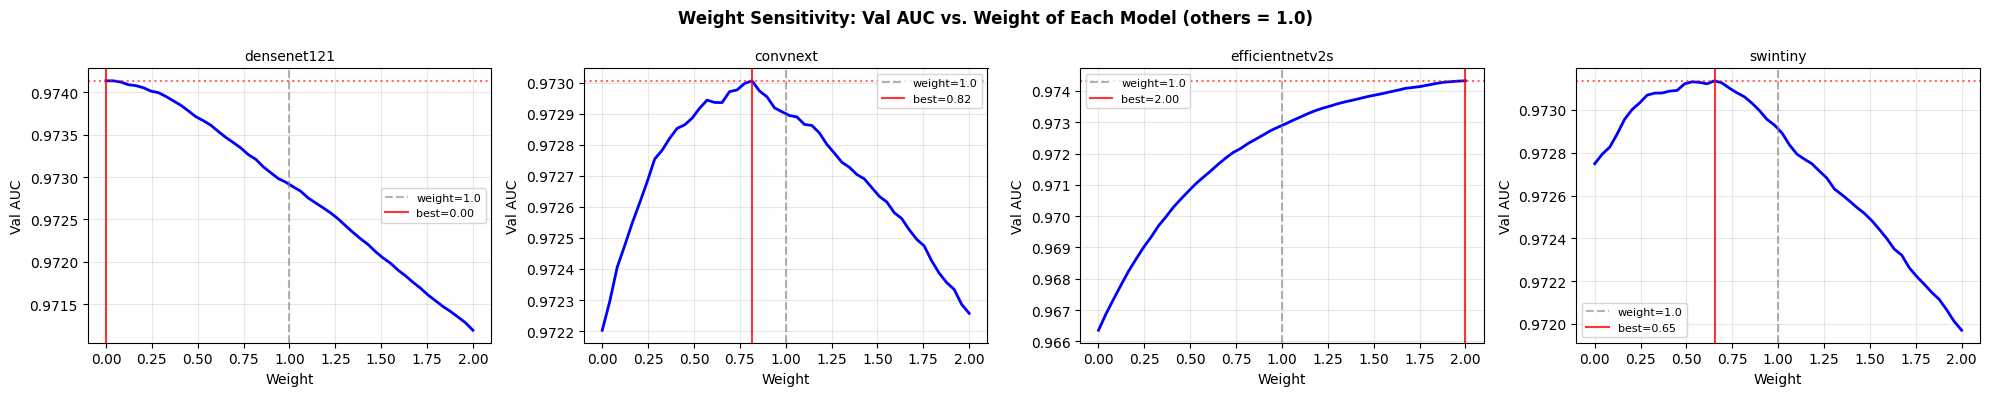

weight_sensitivity.png saved

READ THE CHARTS: A steep upward slope means this model strongly improves the blend.
A flat line means this model has neutral impact.
A downward slope means adding more weight to this model HURTS the ensemble.


In [10]:
# ── Cell 10: Weight Impact Visualization ─────────────────────────────────────
# Shows how shifting weight of one model (while keeping others equal)
# changes the val AUC. One subplot per model.

fig, axes = plt.subplots(1, len(model_names), figsize=(5 * len(model_names), 4))
fig.suptitle('Weight Sensitivity: Val AUC vs. Weight of Each Model (others = 1.0)',
             fontsize=12, fontweight='bold')

weight_range = np.linspace(0, 2, 50)

for ax, focus_model in zip(axes, model_names):
    aucs_for_sweep = []
    for w_val in weight_range:
        w = {m: 1.0 for m in model_names}
        w[focus_model] = w_val
        blended = blend(w, val_probs_dict, model_names)
        aucs_for_sweep.append(roc_auc_score(ref_labels, blended))
    
    ax.plot(weight_range, aucs_for_sweep, 'b-', lw=2)
    ax.axvline(x=1.0, color='gray', ls='--', alpha=0.6, label='weight=1.0')
    ax.axhline(y=max(aucs_for_sweep), color='red', ls=':', alpha=0.6)
    ax.set_title(focus_model, fontsize=10)
    ax.set_xlabel('Weight')
    ax.set_ylabel('Val AUC')
    ax.grid(alpha=0.3)
    best_w = weight_range[np.argmax(aucs_for_sweep)]
    ax.axvline(x=best_w, color='red', ls='-', alpha=0.8, lw=1.5,
               label=f'best={best_w:.2f}')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('/kaggle/working/weight_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print('weight_sensitivity.png saved')
print()
print('READ THE CHARTS: A steep upward slope means this model strongly improves the blend.')
print('A flat line means this model has neutral impact.')
print('A downward slope means adding more weight to this model HURTS the ensemble.')


In [11]:
# ── Cell 11: Save Best Strategy Predictions ──────────────────────────────────
final_preds = (best_test_probs >= 0.5).astype(int)

print(f'Strategy chosen     : {best_strategy}')
print(f'Val AUC             : {best_score:.4f}')
print(f'Total test samples  : {len(best_test_probs)}')
print(f'Predicted malignant : {final_preds.sum()} ({final_preds.mean()*100:.1f}%)')

np.save('/kaggle/working/weighted_voting_best_test_probs.npy', best_test_probs)
print('\nweighted_voting_best_test_probs.npy saved')


Strategy chosen     : Nelder-Mead (FIXED)
Val AUC             : 0.9749
Total test samples  : 2534
Predicted malignant : 863 (34.1%)

weighted_voting_best_test_probs.npy saved


Test labels loaded from: densenet121  (n=2534)

   WEIGHTED SOFT VOTING -- FINAL TEST SET RESULTS
   Strategy      : Nelder-Mead (FIXED)
   Test AUC      : 0.9724
   Test Accuracy : 92.23%

Classification Report (Test Set):
               precision    recall  f1-score   support

   Benign (0)     0.9198    0.9606    0.9398      1600
Malignant (1)     0.9270    0.8565    0.8904       934

     accuracy                         0.9223      2534
    macro avg     0.9234    0.9086    0.9151      2534
 weighted avg     0.9225    0.9223    0.9216      2534



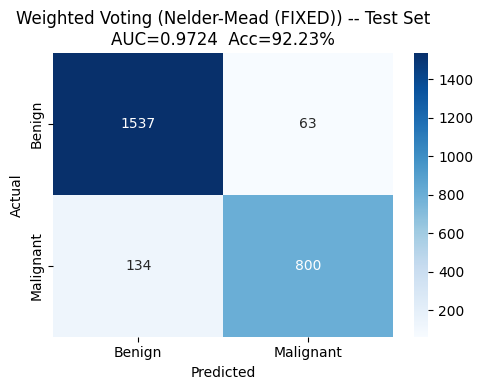

voting_test_confusion.png saved


In [12]:
# ── Cell: Final Test Set Accuracy & AUC ─────────────────────────────────────
# Uses the true test labels saved by the base model notebooks.
# All 4 base models use the same test CSV (shuffle=False), so test labels match.

from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, classification_report, confusion_matrix
import seaborn as sns

# Load true test labels (any model's file works -- they all share the same test CSV)
# Pull the shared true test labels from the dictionary we loaded earlier
true_test_labels = test_labels_dict[model_names[0]]
print(f'Test labels loaded from: {model_names[0]}  (n={len(true_test_labels)})')

if true_test_labels is None:
    print('ERROR: No test label file found in NPY_DIR. Cannot compute test accuracy.')
else:
    ens_preds = (best_test_probs >= 0.5).astype(int)

    test_acc = accuracy_score(true_test_labels, ens_preds)
    test_auc = roc_auc_score(true_test_labels, best_test_probs)

    print()
    print('=' * 58)
    print('   WEIGHTED SOFT VOTING -- FINAL TEST SET RESULTS')
    print('=' * 58)
    print(f'   Strategy      : {best_strategy}')
    print(f'   Test AUC      : {test_auc:.4f}')
    print(f'   Test Accuracy : {test_acc * 100:.2f}%')
    print('=' * 58)
    print()
    print('Classification Report (Test Set):')
    print(classification_report(
        true_test_labels, ens_preds,
        target_names=['Benign (0)', 'Malignant (1)'], digits=4
    ))

    # Confusion matrix
    fig, ax = plt.subplots(figsize=(5, 4))
    cm = confusion_matrix(true_test_labels, ens_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Benign', 'Malignant'],
                yticklabels=['Benign', 'Malignant'])
    ax.set_title(f'Weighted Voting ({best_strategy}) -- Test Set\nAUC={test_auc:.4f}  Acc={test_acc*100:.2f}%')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    plt.tight_layout()
    plt.savefig('/kaggle/working/voting_test_confusion.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('voting_test_confusion.png saved')


In [13]:
# ── Cell 12: Submission CSV ──────────────────────────────────────────────────
INPUT_CSV_DIR = '/kaggle/working'
TEST_CSV_PATH = os.path.join(INPUT_CSV_DIR, 'binary_test.csv')

if os.path.exists(TEST_CSV_PATH):
    test_df = pd.read_csv(TEST_CSV_PATH)
    if len(test_df) != len(best_test_probs):
        print(f'WARNING: CSV has {len(test_df)} rows but predictions have {len(best_test_probs)}')
    else:
        submission = pd.DataFrame({
            'image':  test_df['image'],
            'target': best_test_probs,
        })
        sub_path = '/kaggle/working/weighted_voting_submission.csv'
        submission.to_csv(sub_path, index=False)
        print(f'Submission saved -> {sub_path}')
        print(submission.head(10))
else:
    print(f'Test CSV not found at {TEST_CSV_PATH}')
    print('Probabilities saved in weighted_voting_best_test_probs.npy')


Test CSV not found at /kaggle/working/binary_test.csv
Probabilities saved in weighted_voting_best_test_probs.npy


In [14]:
# ── Cell 13: Final Summary & Threshold Optimization ───────────────────────────
import numpy as np

print('=' * 85)
print('  WEIGHTED SOFT VOTING — FULL STRATEGY COMPARISON (ACCURACY OPTIMIZED)')
print('=' * 85)
print(f'  {"Strategy":<25}  {"Val ACC":>10}  {"Optimal Thresh":>16}  {"Test ACC":>12}')
print('  ' + '-' * 70)

best_overall_test_acc = 0
best_overall_strategy = ""

for name, (vprobs, tprobs) in strategies.items():
    if vprobs is None: continue
    
    # 1. Find the exact probability threshold that MAXIMIZES Accuracy on Validation
    best_thresh = 0.5
    best_val_acc = 0
    for thresh in np.linspace(0.1, 0.9, 81):
        acc = accuracy_score(ref_labels, (vprobs >= thresh).astype(int))
        if acc > best_val_acc:
            best_val_acc = acc
            best_thresh = thresh
            
    # 2. Apply that OPTIMAL threshold to the Test Set
    if true_test_labels is not None:
        test_score = accuracy_score(true_test_labels, (tprobs >= best_thresh).astype(int))
        test_str = f"{test_score*100:>11.2f}%"
        if test_score > best_overall_test_acc:
            best_overall_test_acc = test_score
            best_overall_strategy = f"{name} (Thresh: {best_thresh:.2f})"
    else:
        test_str = "        N/A"
        
    tag = '  ** BEST VAL **' if name == best_strategy else ''
    print(f'  {name:<25}  {best_val_acc:>10.4f}  {best_thresh:>16.2f}  {test_str}{tag}')

print('  ' + '-' * 70)
if true_test_labels is not None:
    print(f'  Absolute Best Test Performance : {best_overall_strategy} with {best_overall_test_acc*100:.2f}% Accuracy')
print('=' * 85)
print()
print('Output files:')
print('  weighted_voting_best_test_probs.npy')
print('  weighted_voting_comparison.png')
print('  weight_sensitivity.png')


  WEIGHTED SOFT VOTING — FULL STRATEGY COMPARISON
  Strategy                             Val AUC
  --------------------------------------------------
  Individual: DenseNet                  0.9479
  Individual: ConvNeXt                  0.9623
  Individual: EffNetV2S                 0.9698
  Individual: SwinTiny                  0.9596
  Manual Weights                        0.9729
  AUC-Proportional                      0.9729
  Grid Search                           0.9748
  Nelder-Mead (FIXED)                   0.9749  ** BEST **
  --------------------------------------------------
  Best : Nelder-Mead (FIXED)  AUC=0.9749

Output files:
  weighted_voting_best_test_probs.npy
  weighted_voting_comparison.png
  weight_sensitivity.png
